In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns 
import pandas as pd
import os

In [2]:
chemin = "../data/ML_data/OncoLien_dataset_complet_simule.xlsx"

# Importation des donnees
if (os.path.exists(chemin)) :
    df = pd.read_excel(chemin, sheet_name = "Suivi_quotidien")
    print("... Chargement Reussit ...")
else :
    print("... Echec Chargement ...")

... Chargement Reussit ...


In [3]:
# 5 premieres lignes
df.head()

,id_patient,date,jour_suivi,questionnaire_rempli,capacite_physique,capacite_travail_loisirs,etat_emotionnel,capacite_cognitive,capacite_sociale,niveau_fatigue,...,appel_infirmiere,globules_blancs_giga_l,hemoglobine_g_dl,grade_jour,alerte_confirmee_infirmiere,urgence_ou_hospitalisation,grade_rouge_7j,urgence_ou_hospitalisation_7j,aggravation_7j,eligible_entrainement
0,P001,2026-07-21,1,1,5.0,2.0,7.0,6.0,6.0,5.0,...,0,7.8,12.4,1.0,NaN,0,0.0,0.0,0.0,1
1,P001,2026-07-22,2,1,5.0,2.0,7.0,6.0,5.0,5.0,...,1,NaN,NaN,1.0,NaN,0,0.0,0.0,0.0,1
2,P001,2026-07-23,3,1,5.0,2.0,7.0,6.0,5.0,4.0,...,0,NaN,NaN,1.0,NaN,0,0.0,0.0,0.0,1
3,P001,2026-07-24,4,1,5.0,2.0,7.0,6.0,6.0,5.0,...,1,NaN,NaN,1.0,NaN,0,0.0,0.0,0.0,1
4,P001,2026-07-25,5,1,5.0,2.0,8.0,6.0,6.0,5.0,...,1,NaN,NaN,1.0,NaN,0,0.0,0.0,0.0,1


In [4]:
# Forme du dataset
df.shape

(12810, 32)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12810 entries, 0 to 12809
Data columns (total 32 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   id_patient                     12810 non-null  object        
 1   date                           12810 non-null  datetime64[ns]
 2   jour_suivi                     12810 non-null  int64         
 3   questionnaire_rempli           12810 non-null  int64         
 4   capacite_physique              11322 non-null  float64       
 5   capacite_travail_loisirs       11322 non-null  float64       
 6   etat_emotionnel                11322 non-null  float64       
 7   capacite_cognitive             11322 non-null  float64       
 8   capacite_sociale               11322 non-null  float64       
 9   niveau_fatigue                 11322 non-null  float64       
 10  niveau_appetit                 11322 non-null  float64       
 11  nausee_vomissem

In [6]:
# Colonnes du dataset
df.columns.to_list()

['id_patient',
 'date',
 'jour_suivi',
 'questionnaire_rempli',
 'capacite_physique',
 'capacite_travail_loisirs',
 'etat_emotionnel',
 'capacite_cognitive',
 'capacite_sociale',
 'niveau_fatigue',
 'niveau_appetit',
 'nausee_vomissement',
 'douleurs_dyspnee_insomnies',
 'niveau_constipation',
 'niveau_diarrhees',
 'chute_cheveux',
 'temperature_c',
 'traitement_pris',
 'jour_dans_cycle',
 'jours_depuis_derniere_dose',
 'nb_cycles_recus',
 'utilisation_chat',
 'appel_infirmiere',
 'globules_blancs_giga_l',
 'hemoglobine_g_dl',
 'grade_jour',
 'alerte_confirmee_infirmiere',
 'urgence_ou_hospitalisation',
 'grade_rouge_7j',
 'urgence_ou_hospitalisation_7j',
 'aggravation_7j',
 'eligible_entrainement']

In [7]:
# Formw apres suppression de donnees
df.shape

(12810, 32)

In [8]:
# A present je me pose la question de savoir si nos donnees peuvent contenir toutes les informations necessaires mentionnees
# sur la mentionner sur le questionnaire medicale. 

<h2>Fusion des donnees importantes des feuilles Patients et Suivi_quotidien</h2>

In [9]:
suivi = pd.read_excel(chemin, sheet_name="Suivi_quotidien")
patients = pd.read_excel(chemin, sheet_name="Patients")

# 1. Colonne 0/1 pour la chimiothérapie
patients["chimio"] = patients["traitements"].str.contains("Chimiotherapie", na=False).astype(int)

# 2. metastase est en oui/non : on la convertit en 0/1
patients["metastase"] = patients["metastase"].map({"oui": 1, "non": 0})

# 3. Durée de maladie : "3 ans" -> 3 (on extrait le nombre)
patients["duree_maladie_ans"] = patients["duree_maladie"].astype(str).str.extract(r"(\d+)").astype(float)

# 4. On garde seulement les colonnes importantes dans patients
cols = ["id_patient", "age", "metastase", "chimio",
        "antecedent_urgences", "antecedent_hospitalisation",
        "n_comorbidites", "ecog_etat_general", "ligne_traitement",
        "duree_cycle_jours", "nb_cycles_avant_suivi", "duree_maladie_ans"]

df = suivi.merge(patients[cols], on="id_patient", how="left")

In [10]:
df.head()

,id_patient,date,jour_suivi,questionnaire_rempli,capacite_physique,capacite_travail_loisirs,etat_emotionnel,capacite_cognitive,capacite_sociale,niveau_fatigue,...,metastase,chimio,antecedent_urgences,antecedent_hospitalisation,n_comorbidites,ecog_etat_general,ligne_traitement,duree_cycle_jours,nb_cycles_avant_suivi,duree_maladie_ans
0,P001,2026-07-21,1,1,5.0,2.0,7.0,6.0,6.0,5.0,...,1,1,0,0,0,2,3,21.0,3.0,3.0
1,P001,2026-07-22,2,1,5.0,2.0,7.0,6.0,5.0,5.0,...,1,1,0,0,0,2,3,21.0,3.0,3.0
2,P001,2026-07-23,3,1,5.0,2.0,7.0,6.0,5.0,4.0,...,1,1,0,0,0,2,3,21.0,3.0,3.0
3,P001,2026-07-24,4,1,5.0,2.0,7.0,6.0,6.0,5.0,...,1,1,0,0,0,2,3,21.0,3.0,3.0
4,P001,2026-07-25,5,1,5.0,2.0,8.0,6.0,6.0,5.0,...,1,1,0,0,0,2,3,21.0,3.0,3.0


In [11]:
# Informations du dataset
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12810 entries, 0 to 12809
Data columns (total 43 columns):
 #   Column                         Non-Null Count  Dtype         
---  ------                         --------------  -----         
 0   id_patient                     12810 non-null  object        
 1   date                           12810 non-null  datetime64[ns]
 2   jour_suivi                     12810 non-null  int64         
 3   questionnaire_rempli           12810 non-null  int64         
 4   capacite_physique              11322 non-null  float64       
 5   capacite_travail_loisirs       11322 non-null  float64       
 6   etat_emotionnel                11322 non-null  float64       
 7   capacite_cognitive             11322 non-null  float64       
 8   capacite_sociale               11322 non-null  float64       
 9   niveau_fatigue                 11322 non-null  float64       
 10  niveau_appetit                 11322 non-null  float64       
 11  nausee_vomissem

<h2> Description des donnees </h2>

<table border  = "collapse" border = "2px solid black" textAlign = "center">
    <tr>
        <th> Colonne </th>
        <th> Importance/Role </th>
        <th>A conserver ?</th>
    </tr>
    <tr>
        <td>id_patient </td>
        <td>Identifiant du patient</td>
        <td> Va servir dans l'anlyse mais pas dans la prediction </td>
    </tr>
    <tr>
        <td>jour_suivi</td>
        <td>Le nombre de jours depuis le debut du suivi</td>
        <td>Pourra peut etre servir dans l'analyse</td>
    </tr>
    <tr>
        <td>date</td>
        <td>Date de suivi</td>
        <td>Oui</td>
    </tr>
    <tr>
        <td> questionnaire_rempli </td>
        <td>Vaut 0 si le patient n'a pas donne d'etat ou de nouvelle le jour en question et 1 dans le cas contraire</td>
        <td>Oui</td>
    </tr>
    <tr>
        <td>traitement_pris</td>
        <td>Vaut 0 si le patient n'a pas pris de traitement je jour en question, 1 dans le cas contraire</td>
        <td>Oui</td>
    </tr>
    <tr>
        <td>jour_dans_cycle </td>
        <td>Le nombre de jour apres administration d'une chimiotherapie</td>
        <td>Oui</td>
    </tr>
    <tr>
        <td>jours_depuis_derniere_dose</td>
        <td>Nombre de jour depuis la dernier dose de chimiotherapie</td>
        <td>Non, car est calcule a partir de jour_dans_cycle</td>
    </tr>
    <tr>
        <td>nb_cycles_recus</td>
        <td>Nombre de cycle de jours apres avoir recus une chimiotherapie</td>
        <td>Oui</td>
    </tr>
    <tr>
        <td>utilisation_chat</td>
        <td>Nombre d'utilisation de l'assistant IA dans un jour</td>
        <td>Non, car l'assistant non existant</td>
    </tr>
    <tr>
        <td>appel_infirmiere</td>
        <td>Vaut 1 si l'infirmiere a appele le patient apres avoir constate que son etat(grade) s'est agrave et 0 dans le cas contraire</td>
        <td>Non, car cette variable est une consequence de la prediction de l'aggravation du grade et intervient apres la prediction</td>
    </tr>
    <tr>
        <td>globules_blancs_giga_l </td>
        <td>Entrée forte. Une baisse (neutropénie) rend une fièvre dangereuse. Mesurée
chaque semaine : reportez la dernière valeur connue (forward fill par patient,
jamais en arrière) et ajoutez le nombre de jours depuis la mesure. Utile seulement
si l'application peut récupérer les prises de sang.</td>
        <td>Non car, le patient peut ne pas avoir d'information sur sa prise de sang</td>
    </tr>
    <tr>
        <td>hemoglobine_g_dl </td>
        <td>Entrée conditionnelle. Une baisse signale l'anémie (fatigue, essoufflement), mais le
lien direct avec l'aggravation à 7 jours est plus faible. Même traitement des valeurs
manquantes que les globules blancs.</td>
        <td>Non</td>
    </tr>
    <tr>
        <td>grade_jour</td>
        <td>Résumé du jour (0 vert, 1 orange, 2 rouge) calculé à partir des symptômes et de la
température. Redondant avec les symptômes. Utile surtout en tendance (grades
des 3 derniers jours).</td>
        <td>Non car elle calcule a partir d'autre colonne</td>
    </tr>
    <tr>
        <td>alerte_infirmiere</td>
        <td>Elle sert à fabriquer la cible. aggravation_7j compte un grade rouge seulement s’il est confirmé par l’infirmière. Cette colonne fait donc partie de la définition de ce que l'on prédis.
Elle est une conséquence de l’état. L’infirmière confirme parce que le patient va déjà mal. Le modèle apprendrait « alerte confirmée = problème », sans prévoir quoi que ce soit à l’avance.</td>
        <td>Non</td>
    </tr>
    <tr>
        <td> urgence_ou_hospitalisation </td>
        <td>Événement qui sert à fabriquer la cible. L'utiliser comme entrée revient à donner la
réponse au modèle.</td>
        <td>Non</td>
    </tr>
    <tr>
        <td>aggravation_7j</td>
        <td>Variable cible, Cible principale : 1 si un grade rouge confirmé, un passage aux urgences ou une
hospitalisation survient entre D+1 et D+7. Vide pour les 7 derniers jours de chaque
patient (futur inconnu), d'où le filtre eligible_entrainement.</td>
        <td>Oui</td>
    </tr>
    <tr>
        <td>grade_rouge_7j, urgence_ou_hospitalisation_7j</td>
        <td>Fait partie de la définition de
aggravation_7j</td>
        <td>Non</td>
    </tr>
    <tr>
        <td>eligible_entrainement</td>
        <td>il dit quelles lignes ont le droit d’être utilisées pour entraîner et tester le modèle. Ce n’est pas une variable à donner au modèle.
            Elle vaut 1 quand les trois conditions sont réunies (d’après le PDF) :

La cible est connue. Les 7 derniers jours de chaque patient n’ont pas de aggravation_7j, car on ne connaît pas leur futur.
La fiche du jour est remplie. Sans réponse, on n’a pas de symptômes à donner au modèle.
Le patient n’est pas déjà en rouge. Prédire une aggravation chez quelqu’un qui est déjà au plus mal n’a pas d’intérêt : l’alerte est déjà là. </td>
        <td>Oui, mais a retirer pour l'entranement</td>
    </tr>
    <tr>
        <td>age </td>
        <td>Le risque de complications augmente avec l'âge.</td>
        <td>Oui</td>
    </tr>
    <tr>
        <td>metastase  </td>
        <td>Maladie avancée, donc risque plus élevé. Entrée forte.</td>
        <td>Oui</td>
    </tr>
    <tr>
        <td>chimio</td>
        <td>chimio est la colonne que nous avons créée à partir du texte de traitements. Elle vaut 1 si le patient est sous chimiothérapie, 0 sinon.</td>
        <td>Oui, C’est le facteur de risque principal pour une aggravation à 7 jours (infections, creux du cycle).</td>
    </tr>
    <tr>
        <td>antecedent_urgences, antecedent_hospitalisation,n_comorbidites </td>
        <td>Plus il y en a, plus le corps est fragile et plus une complication est probable.</td>
        <td>Oui</td>
    </tr>
    <tr>
        <td>ecog_etat_general</td>
        <td>Score d'état général du patient : plus il est dégradé, plus le risque est élevé.</td>
        <td>Oui</td>
    </tr>
    <tr>
        <td>ligne_traitement</td>
        <td>ligne_traitement est le numéro de la ligne de traitement que le patient reçoit actuellement.

Ce que ça veut dire

1re ligne : le premier traitement donné pour cette maladie.
2e ligne : le traitement qui suit quand le premier ne marche plus ou que la maladie revient.
3e ligne et plus : traitements suivants, quand les précédents ont échoué.</td>
        <td>Oui</td>
    </tr>
    <tr>
        <td>duree_cycle_jours,
nb_cycles_avant_suivi</td>
        <td>duree_cycle_jours donne le calendrier de toxicité. Avec un cycle de 21 jours, le creux est vers le jour 10. Avec 14 ou 28 jours, il est décalé et moins marqué. Elle permet au modèle de bien interpréter jour_dans_cycle.
nb_cycles_avant_suivi mesure l’accumulation : plus un patient a reçu de cycles, plus la fatigue et la toxicité s’accumulent.</td>
        <td>Oui</td>
    </tr>
    <tr>
        <td>duree_maladie_ans </td>
        <td> est le nombre d’années écoulées depuis le diagnostic du cancer. </td>
        <td>Oui</td>
    </tr>
    
</table>

In [12]:
colonne_a_supprimer = [
    "jours_depuis_derniere_dose",
    "utilisation_chat",
    "grade_rouge_7j", 
    "urgence_ou_hospitalisation_7j", 
    "urgence_ou_hospitalisation",
    "grade_jour",
    "hemoglobine_g_dl",
    "globules_blancs_giga_l",
    "appel_infirmiere",
]

In [13]:
df.drop(colonne_a_supprimer, axis = 1, inplace = True)

In [14]:
df.shape

(12810, 34)

In [15]:
df.dtypes

id_patient                             object
date                           datetime64[ns]
jour_suivi                              int64
questionnaire_rempli                    int64
capacite_physique                     float64
capacite_travail_loisirs              float64
etat_emotionnel                       float64
capacite_cognitive                    float64
capacite_sociale                      float64
niveau_fatigue                        float64
niveau_appetit                        float64
nausee_vomissement                    float64
douleurs_dyspnee_insomnies            float64
niveau_constipation                   float64
niveau_diarrhees                      float64
chute_cheveux                         float64
temperature_c                         float64
traitement_pris                       float64
jour_dans_cycle                       float64
nb_cycles_recus                       float64
alerte_confirmee_infirmiere           float64
aggravation_7j                    

In [16]:
df.columns.to_list()

['id_patient',
 'date',
 'jour_suivi',
 'questionnaire_rempli',
 'capacite_physique',
 'capacite_travail_loisirs',
 'etat_emotionnel',
 'capacite_cognitive',
 'capacite_sociale',
 'niveau_fatigue',
 'niveau_appetit',
 'nausee_vomissement',
 'douleurs_dyspnee_insomnies',
 'niveau_constipation',
 'niveau_diarrhees',
 'chute_cheveux',
 'temperature_c',
 'traitement_pris',
 'jour_dans_cycle',
 'nb_cycles_recus',
 'alerte_confirmee_infirmiere',
 'aggravation_7j',
 'eligible_entrainement',
 'age',
 'metastase',
 'chimio',
 'antecedent_urgences',
 'antecedent_hospitalisation',
 'n_comorbidites',
 'ecog_etat_general',
 'ligne_traitement',
 'duree_cycle_jours',
 'nb_cycles_avant_suivi',
 'duree_maladie_ans']

In [17]:
# informations
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12810 entries, 0 to 12809
Data columns (total 34 columns):
 #   Column                       Non-Null Count  Dtype         
---  ------                       --------------  -----         
 0   id_patient                   12810 non-null  object        
 1   date                         12810 non-null  datetime64[ns]
 2   jour_suivi                   12810 non-null  int64         
 3   questionnaire_rempli         12810 non-null  int64         
 4   capacite_physique            11322 non-null  float64       
 5   capacite_travail_loisirs     11322 non-null  float64       
 6   etat_emotionnel              11322 non-null  float64       
 7   capacite_cognitive           11322 non-null  float64       
 8   capacite_sociale             11322 non-null  float64       
 9   niveau_fatigue               11322 non-null  float64       
 10  niveau_appetit               11322 non-null  float64       
 11  nausee_vomissement           11322 non-nu

In [18]:
# Valeurs manquantes
df.isna().sum()

id_patient                         0
date                               0
jour_suivi                         0
questionnaire_rempli               0
capacite_physique               1488
capacite_travail_loisirs        1488
etat_emotionnel                 1488
capacite_cognitive              1488
capacite_sociale                1488
niveau_fatigue                  1488
niveau_appetit                  1488
nausee_vomissement              1488
douleurs_dyspnee_insomnies      1488
niveau_constipation             1488
niveau_diarrhees                1488
chute_cheveux                   1488
temperature_c                   1488
traitement_pris                 1364
jour_dans_cycle                 2520
nb_cycles_recus                 2520
alerte_confirmee_infirmiere    12125
aggravation_7j                  2135
eligible_entrainement              0
age                                0
metastase                          0
chimio                             0
antecedent_urgences                0
a

In [19]:
df.isna().mean() * 100

id_patient                      0.000000
date                            0.000000
jour_suivi                      0.000000
questionnaire_rempli            0.000000
capacite_physique              11.615925
capacite_travail_loisirs       11.615925
etat_emotionnel                11.615925
capacite_cognitive             11.615925
capacite_sociale               11.615925
niveau_fatigue                 11.615925
niveau_appetit                 11.615925
nausee_vomissement             11.615925
douleurs_dyspnee_insomnies     11.615925
niveau_constipation            11.615925
niveau_diarrhees               11.615925
chute_cheveux                  11.615925
temperature_c                  11.615925
traitement_pris                10.647931
jour_dans_cycle                19.672131
nb_cycles_recus                19.672131
alerte_confirmee_infirmiere    94.652615
aggravation_7j                 16.666667
eligible_entrainement           0.000000
age                             0.000000
metastase       

In [20]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
date,12810,2026-05-20 12:09:26.557376768,2026-01-05 00:00:00,2026-03-28 00:00:00,2026-05-20 00:00:00,2026-07-13 00:00:00,2026-10-03 00:00:00,NaN
jour_suivi,12810.0,21.5,1.0,11.0,21.5,32.0,42.0,12.121392
questionnaire_rempli,12810.0,0.883841,0.0,1.0,1.0,1.0,1.0,0.320428
capacite_physique,11322.0,5.471736,1.0,4.0,5.0,7.0,10.0,2.053508
capacite_travail_loisirs,11322.0,5.449302,1.0,4.0,6.0,7.0,10.0,2.074008
etat_emotionnel,11322.0,5.452394,1.0,4.0,6.0,7.0,10.0,2.091385
capacite_cognitive,11322.0,5.548843,1.0,4.0,6.0,7.0,10.0,2.007791
capacite_sociale,11322.0,5.391539,1.0,4.0,6.0,7.0,10.0,2.118045
niveau_fatigue,11322.0,5.423158,1.0,4.0,6.0,7.0,10.0,2.192358
niveau_appetit,11322.0,5.429959,1.0,4.0,6.0,7.0,10.0,2.13072


In [21]:
# valeur de la variable cible aggravation_7j
df['aggravation_7j'].value_counts()

aggravation_7j
0.0    9008
1.0    1667
Name: count, dtype: int64

In [22]:
df.describe(include = 'object').T

,count,unique,top,freq
id_patient,12810,305,P001,42


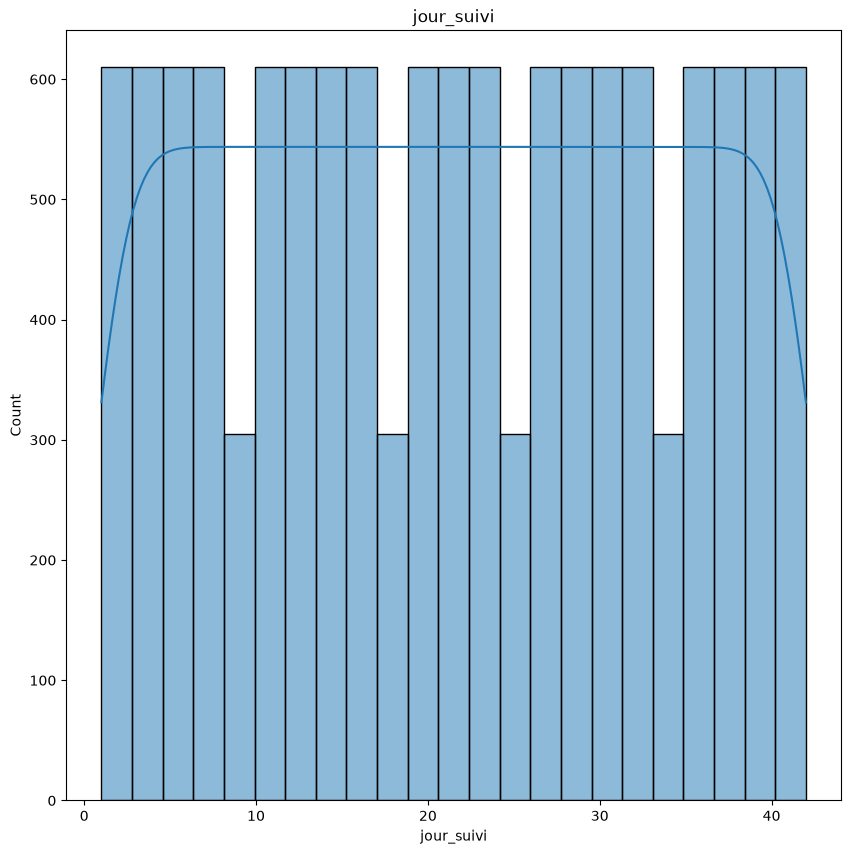

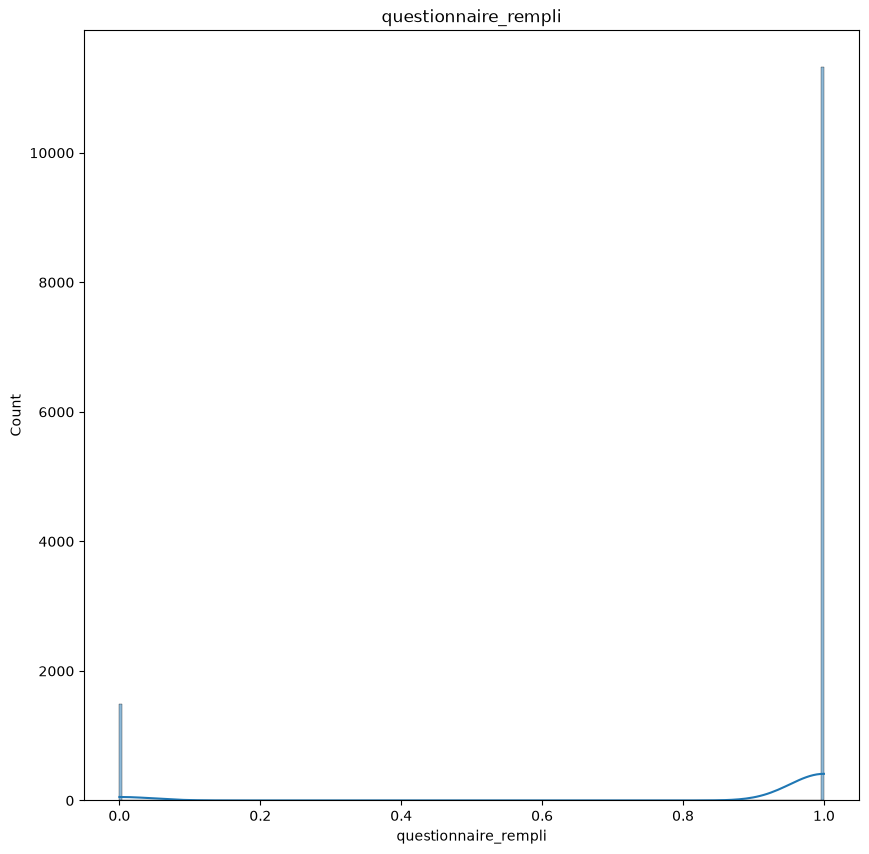

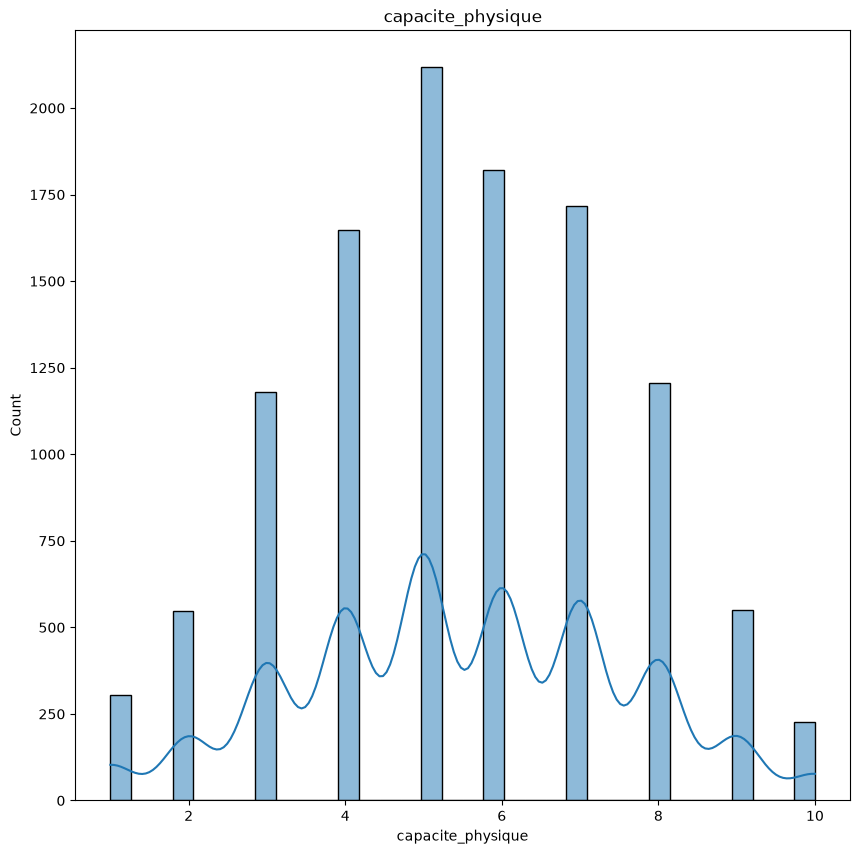

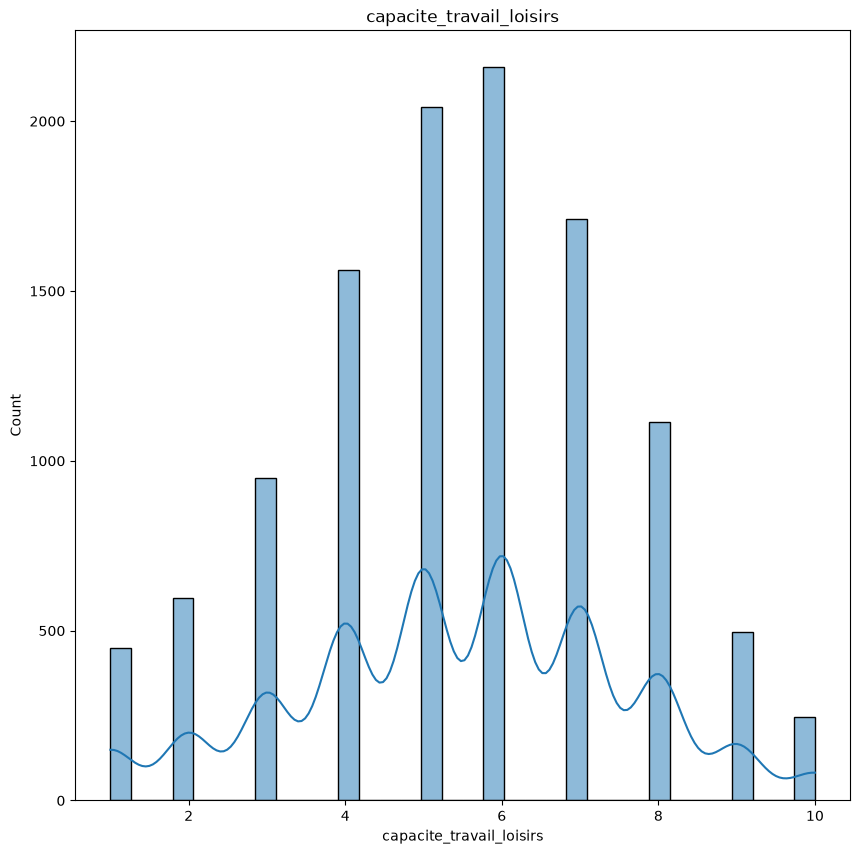

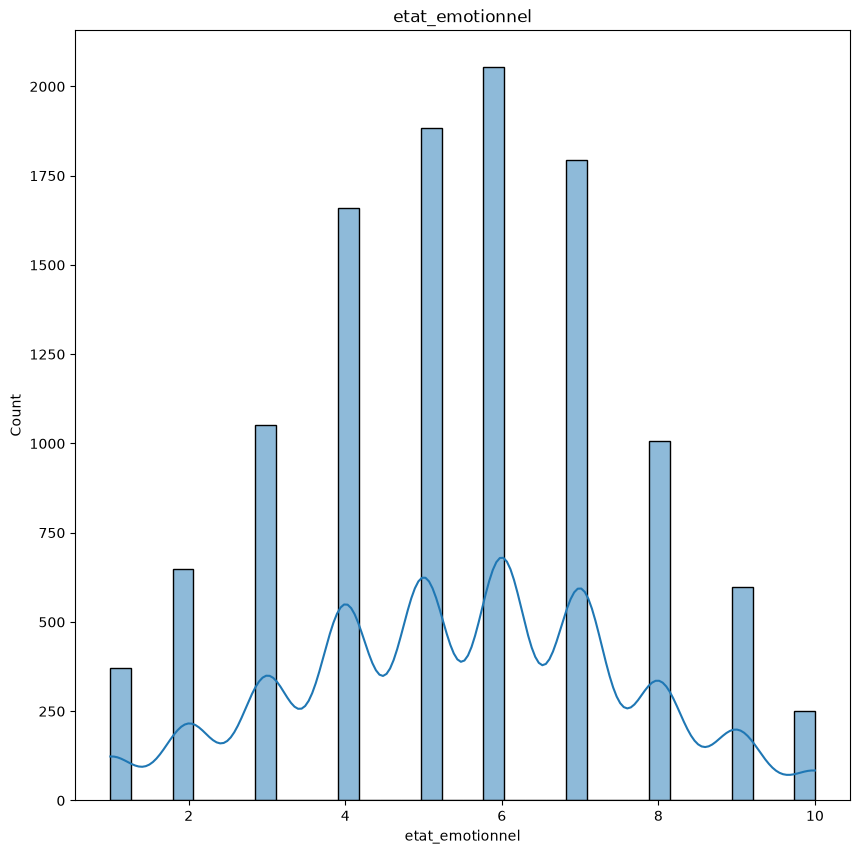

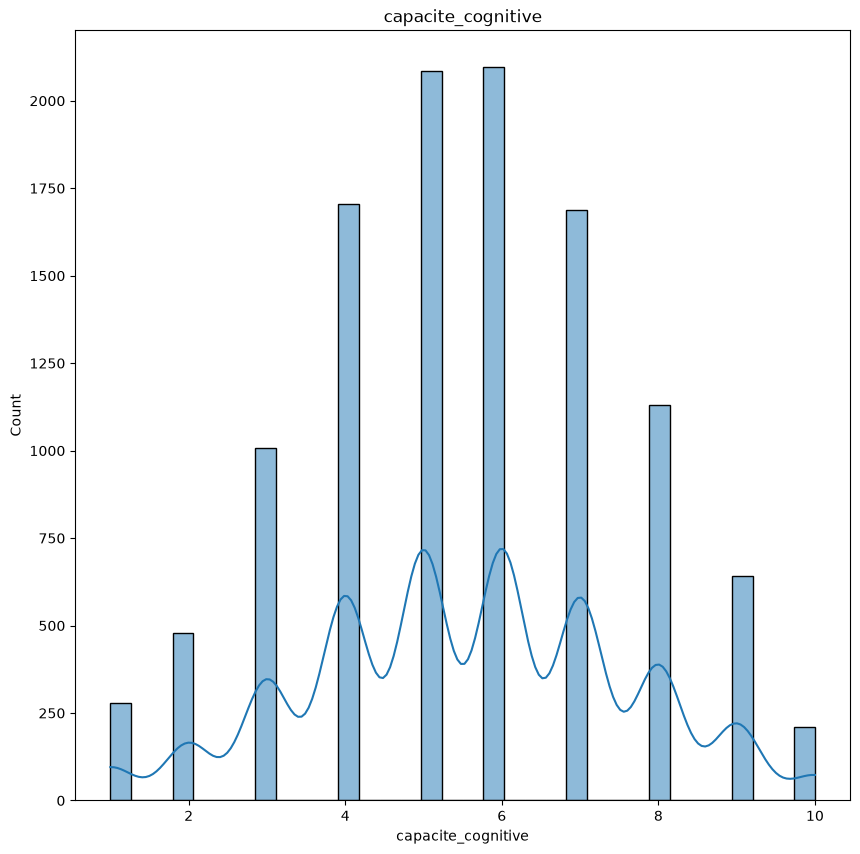

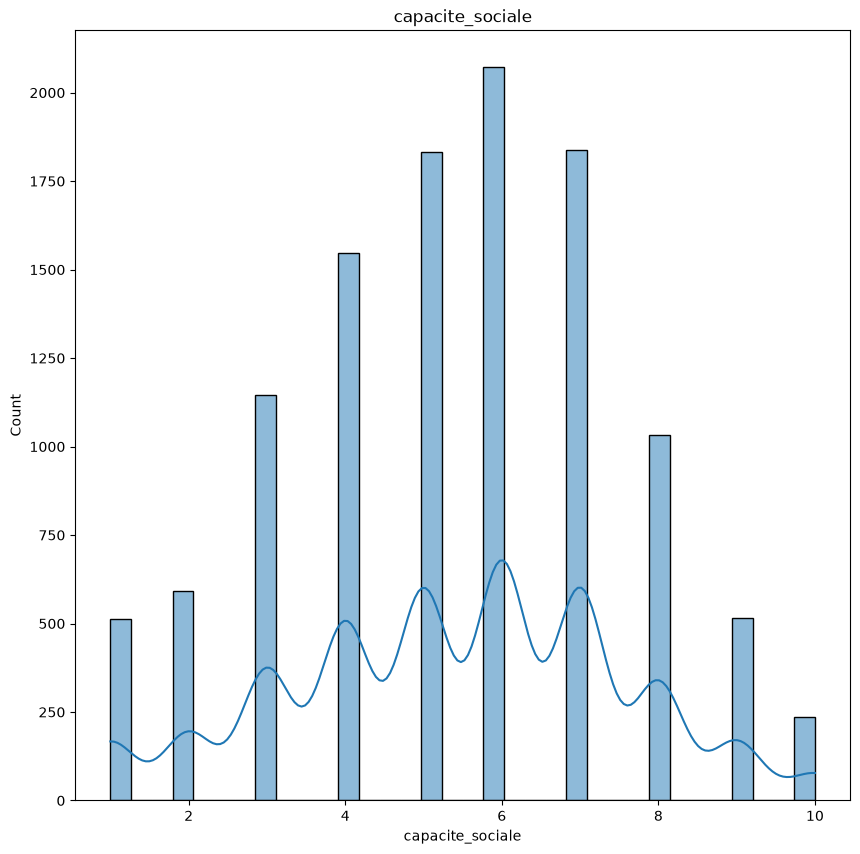

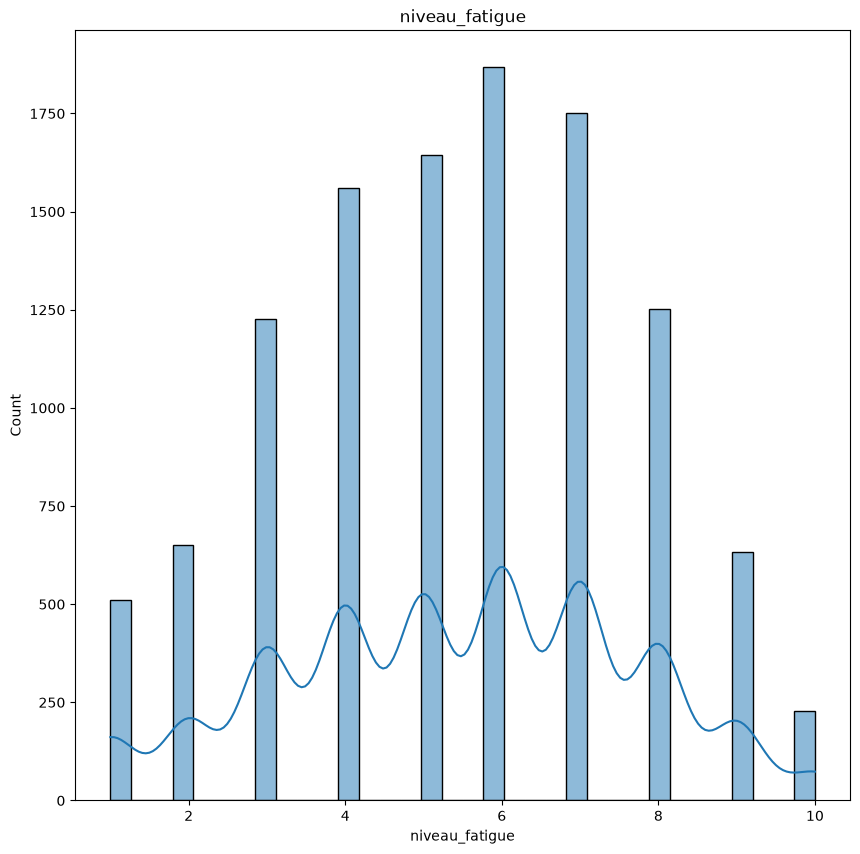

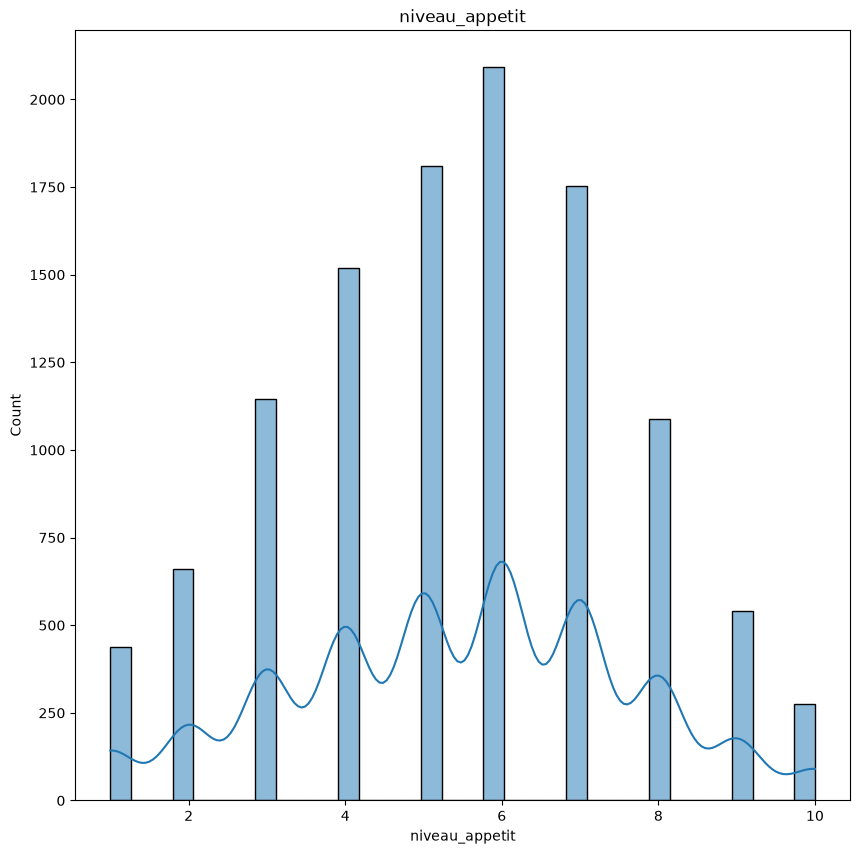

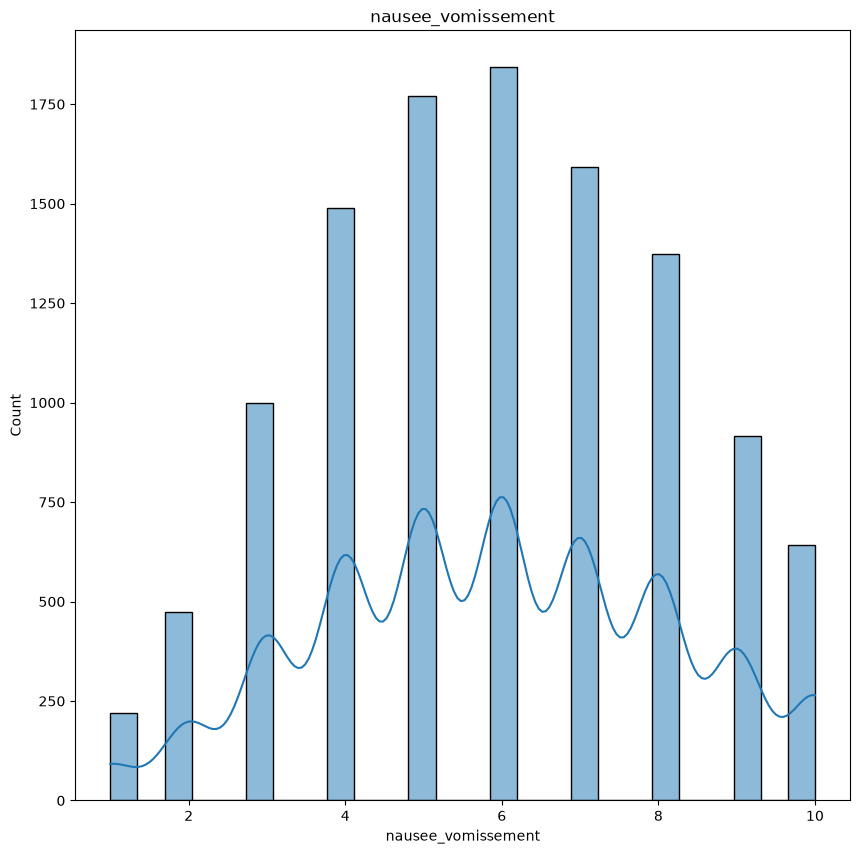

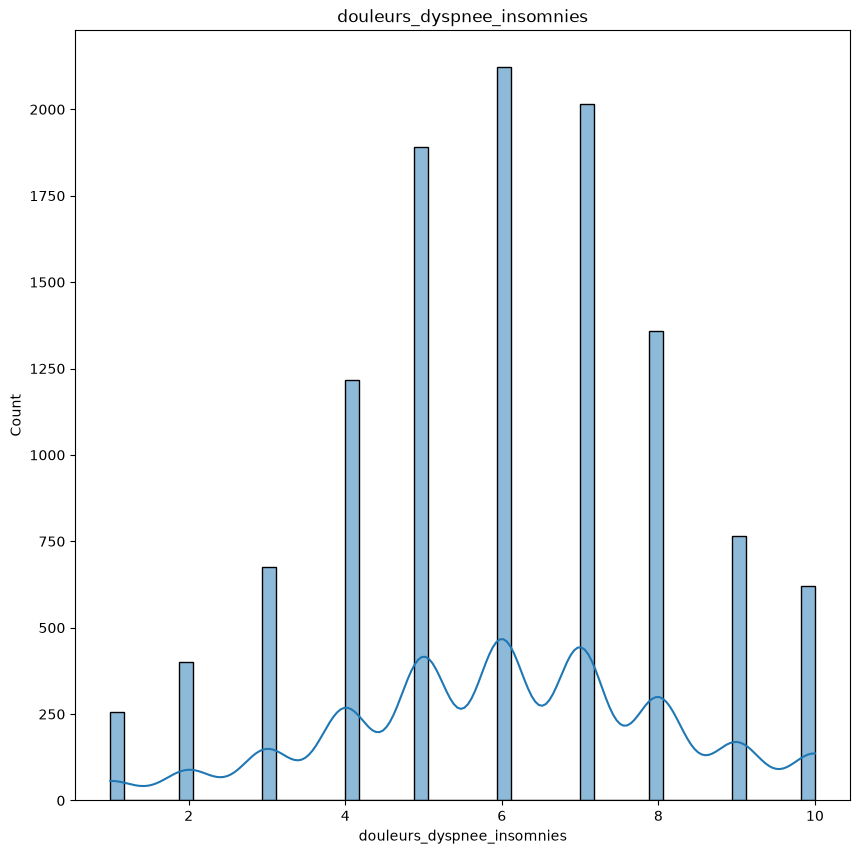

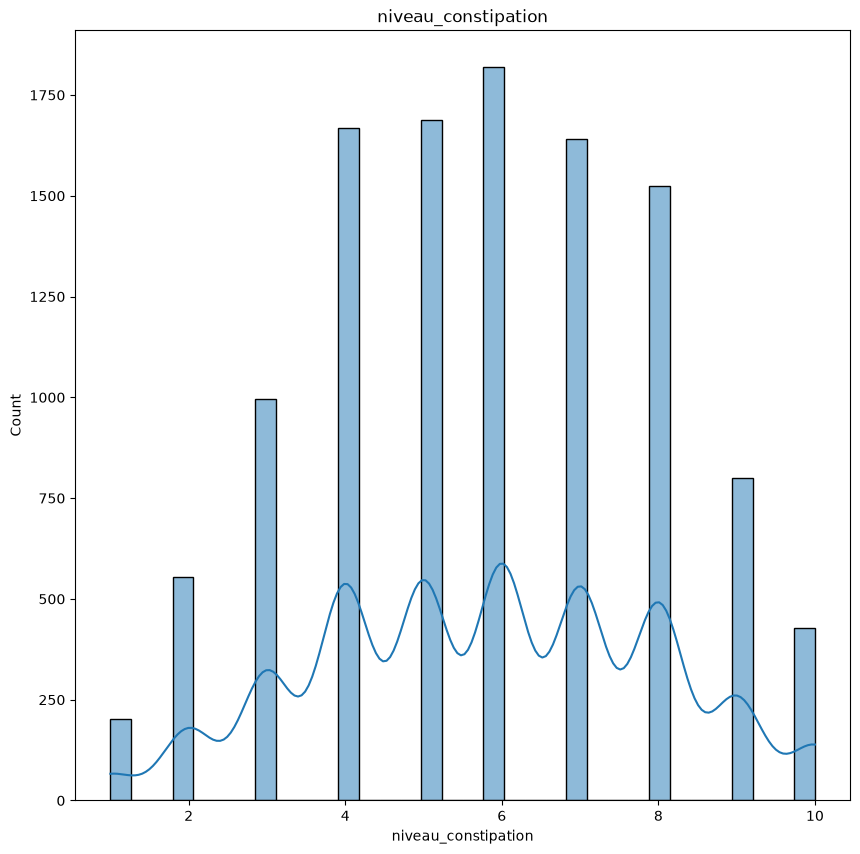

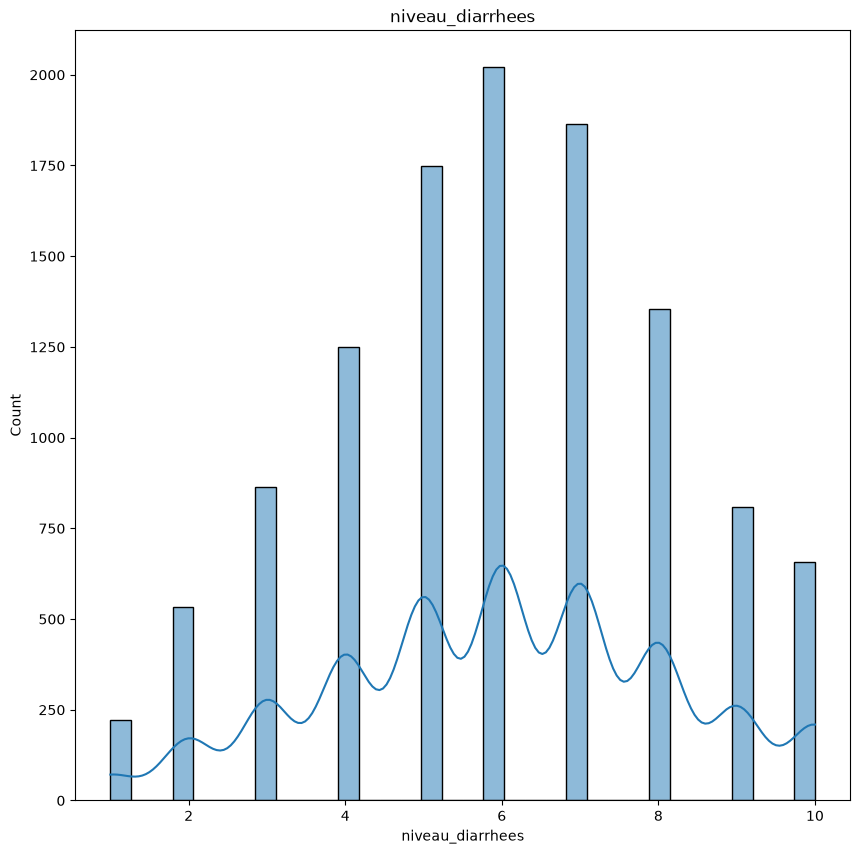

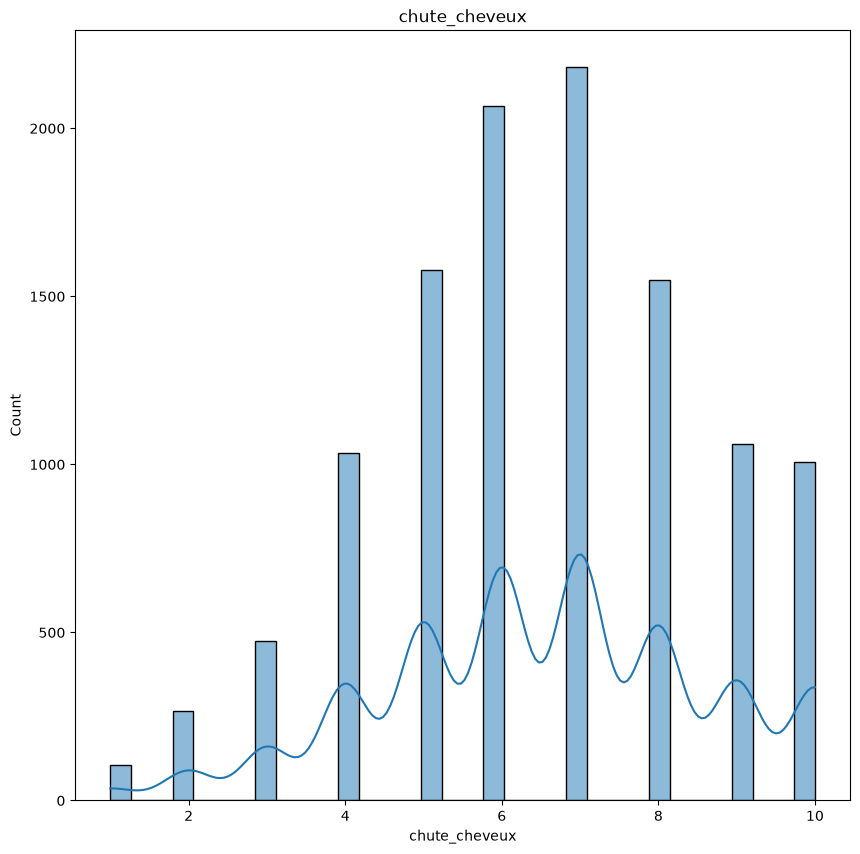

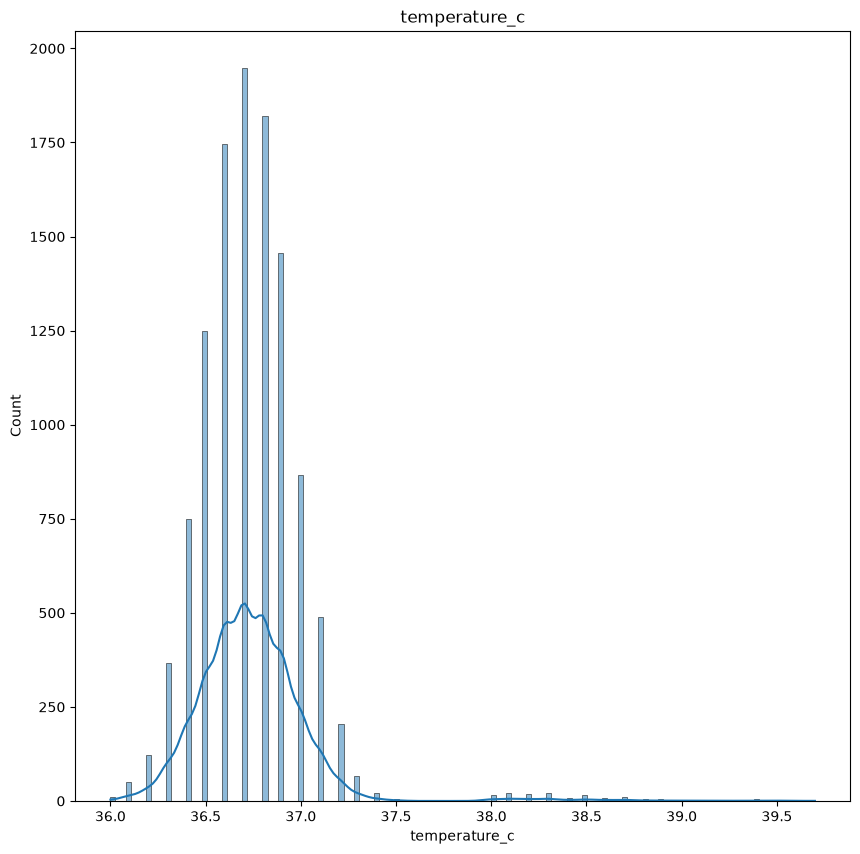

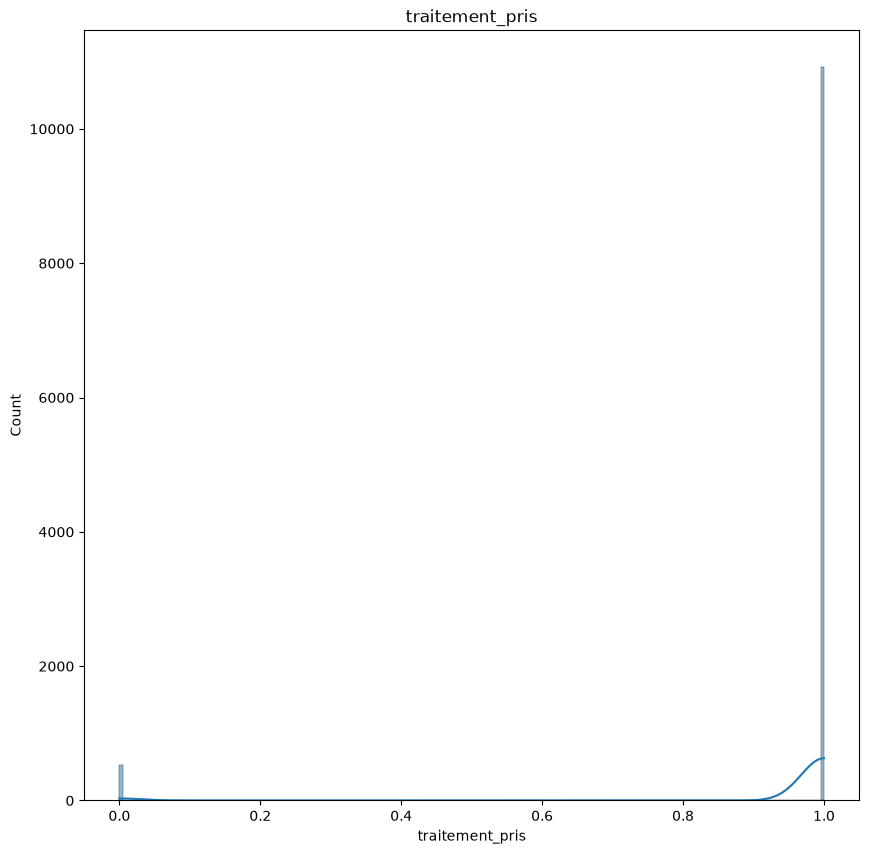

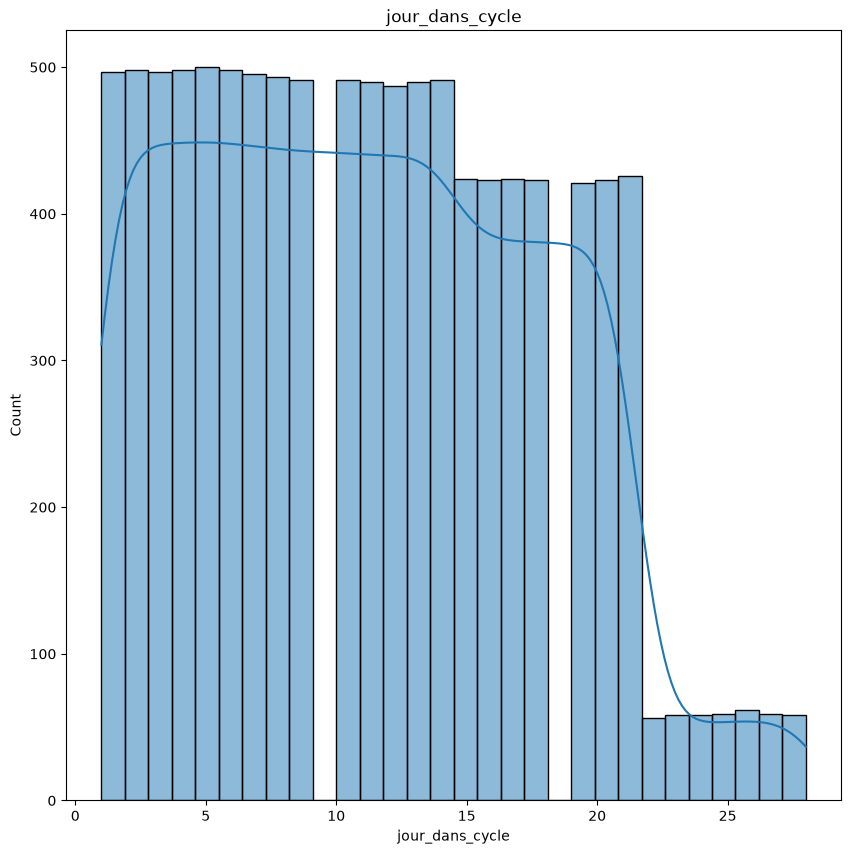

In [23]:
colonne_numerique = df.select_dtypes(include = 'number').columns.to_list()
plage_affichage = len(colonne_numerique)//2 + 1

for i, col in zip(range(plage_affichage), df.select_dtypes(include = 'number').columns.to_list()):
    plt.figure(figsize=(10, 10))
    sns.histplot(df[col].dropna(), kde = True)
    plt.title(col)
    plt.show()

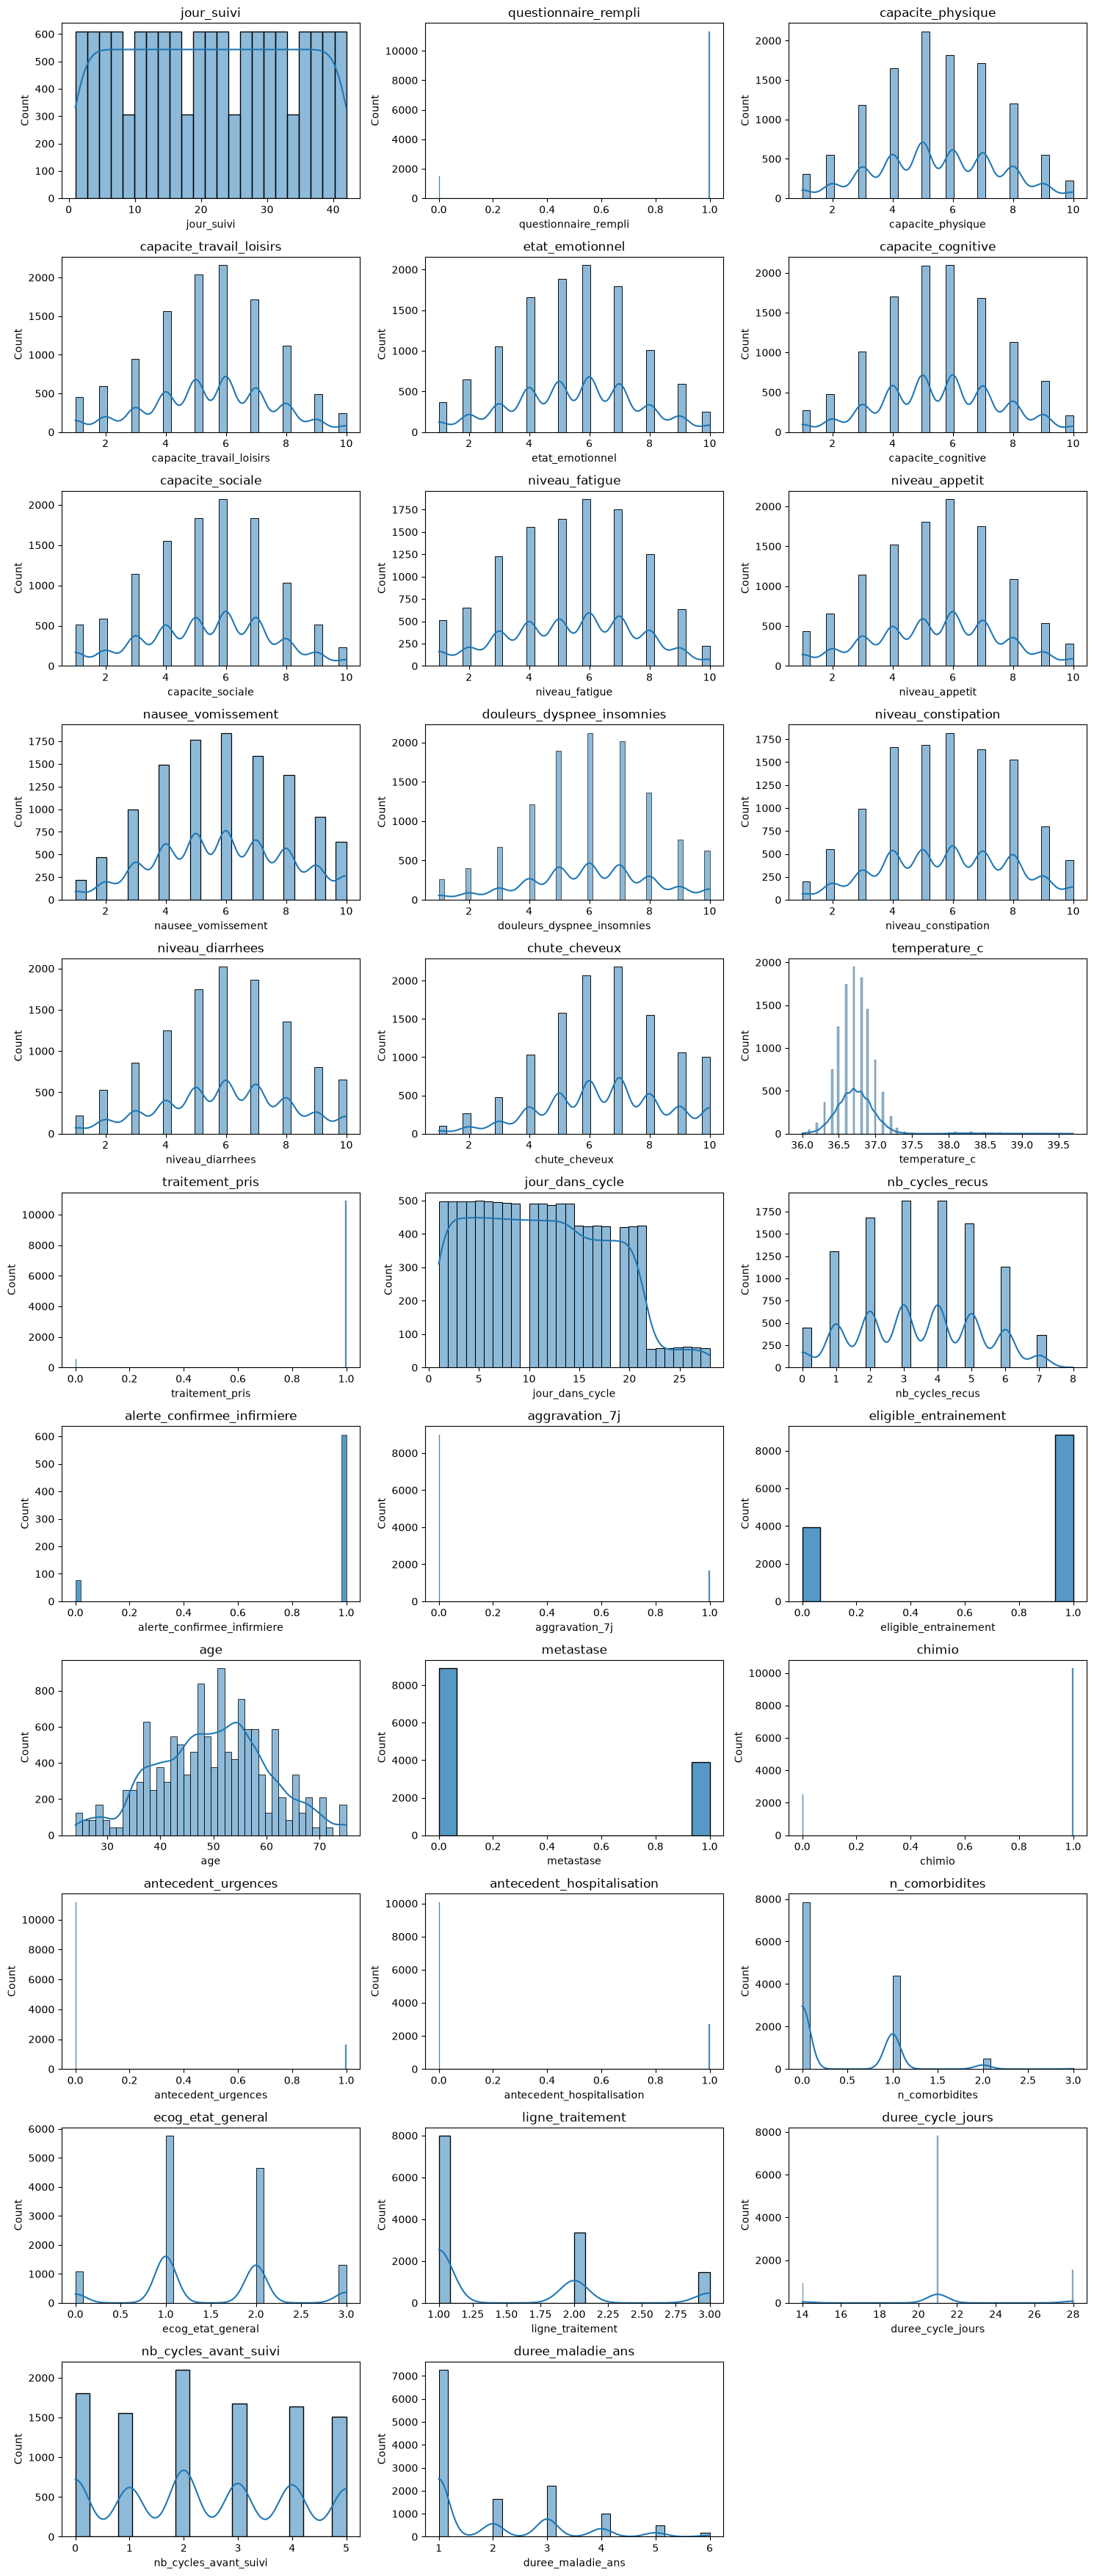

In [24]:
import math
import matplotlib.pyplot as plt
import seaborn as sns

colonnes = df.select_dtypes(include="number").columns.to_list()
n_colonnes_graphe = 3                                   # graphes par ligne
n_lignes = math.ceil(len(colonnes) / n_colonnes_graphe)  # arrondi vers le haut

plt.figure(figsize=(15, 3.2 * n_lignes))                 # 3,2 pouces de haut par ligne
for i, col in enumerate(colonnes, start=1):              # toutes les colonnes
    plt.subplot(n_lignes, n_colonnes_graphe, i)
    sns.histplot(df[col].dropna(), kde=df[col].nunique() > 2)
    plt.title(col)
plt.tight_layout()
plt.show()